## Imports

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from time import perf_counter

In [15]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 8]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Задание 3

In [16]:
a = np.array([1, 2, 4, 5, 19] * 100)
b = np.array([3, 7, 5, 10, 10] * 100)
a = a.reshape((-1, 1))
b = b.reshape((-1, 1))

start_time = perf_counter()
total_sum = 0
for i in range(len(a)):
    total_sum += a[i] * b[i]
result_1 = total_sum
time_1 = perf_counter() - start_time

start_time = perf_counter()
result_2 = np.sum(a * b)
time_2 = perf_counter() - start_time

start_time = perf_counter()
result_3 = a.T @ b
time_3 = perf_counter() - start_time

print(f"Результат цикла: {result_1[0]}")
print(f"Результат метода sum: {result_2}")
print(f"Результат векторного произведения: {result_3[0][0]}")
print()

print(f"Время цикла: {time_1 * 10**6:.0f} микросекунд")
print(f"Время метода sum: {time_2 * 10**6:.0f} микросекунд")
print(f"Время векторного произведения: {time_3 * 10**6:.0f} микросекунд")

Результат цикла: 27700
Результат метода sum: 27700
Результат векторного произведения: 27700

Время цикла: 4901 микросекунд
Время метода sum: 171 микросекунд
Время векторного произведения: 119 микросекунд


## Задание 4

In [17]:
def linear_regression(xs, theta):
    return xs * theta

def cost_function(xs, ys, theta):
    m = len(xs)
    return 1 / (2 * m) * np.sum((linear_regression(xs, theta) - ys)**2)

### Исходные данные

In [18]:
xs1 = np.arange(1, 21)
ys1 = xs1.copy()

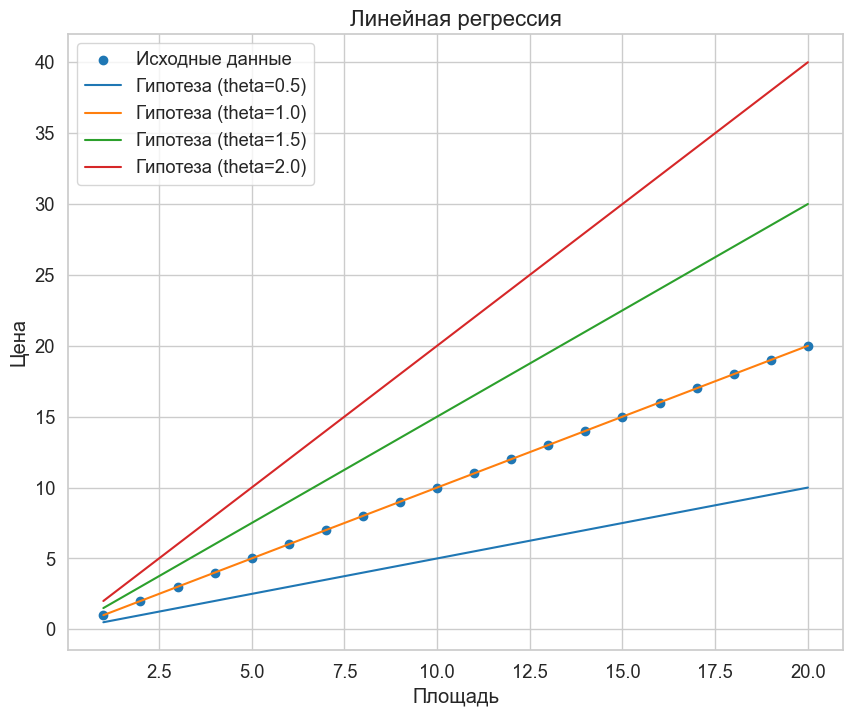

In [28]:
plt.scatter(xs1, ys1, label="Исходные данные")
thetas = [0.5, 1.0, 1.5, 2.0]
for theta in thetas:
    plt.plot(xs1, linear_regression(xs1, theta), label=f"Гипотеза (theta={theta})")
plt.legend()

plt.title("Линейная регрессия", fontsize=16)
plt.xlabel("Площадь")
plt.ylabel("Цена")
plt.show()

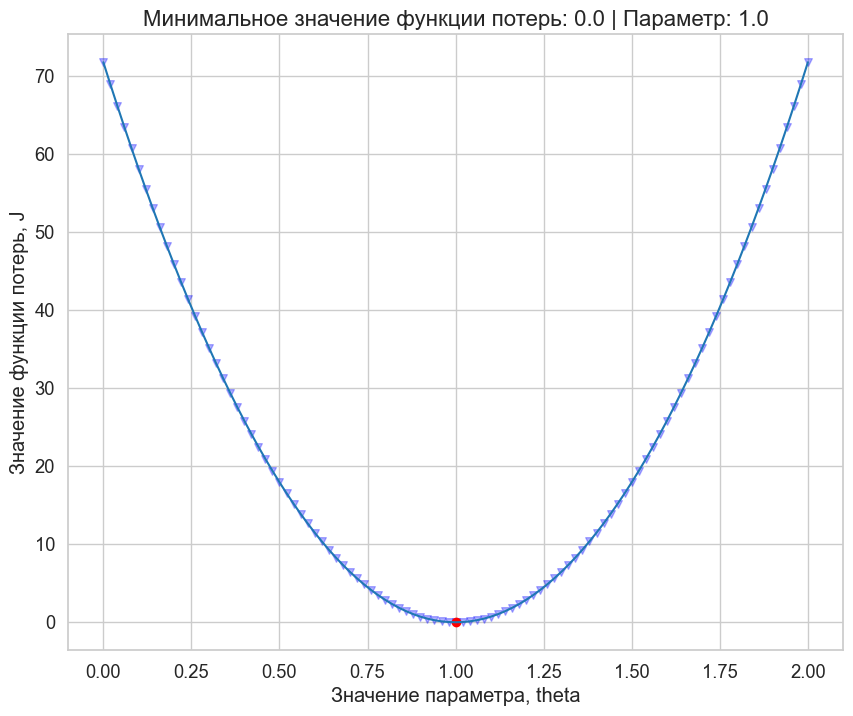

In [20]:
theta_data_1 = np.linspace(0, 2, 101)
cost_function_data_1 = [cost_function(xs1, ys1, theta) for theta in theta_data_1]

plt.plot(theta_data_1, cost_function_data_1)
plt.scatter(theta_data_1, cost_function_data_1, color='blue', alpha=0.3, s=30, marker="v")
plt.xlabel("Значение параметра, theta")
plt.ylabel("Значение функции потерь, J")

mask = cost_function_data_1 == min(cost_function_data_1)
min_function = np.array(cost_function_data_1)[mask]
min_theta = np.array(theta_data_1)[mask]
plt.scatter(min_theta, min_function, color='red')

min_val = min(cost_function_data_1)
plt.title(f"Минимальное значение функции потерь: {min_function[0]} | Параметр: {min_theta[0]}", fontsize=16)

plt.show()

### Зашумленные данные

In [21]:
xs2 = np.arange(1, 21)
ys2 = abs(xs2 + np.random.uniform(-2, 2, size=xs2.shape[0]))

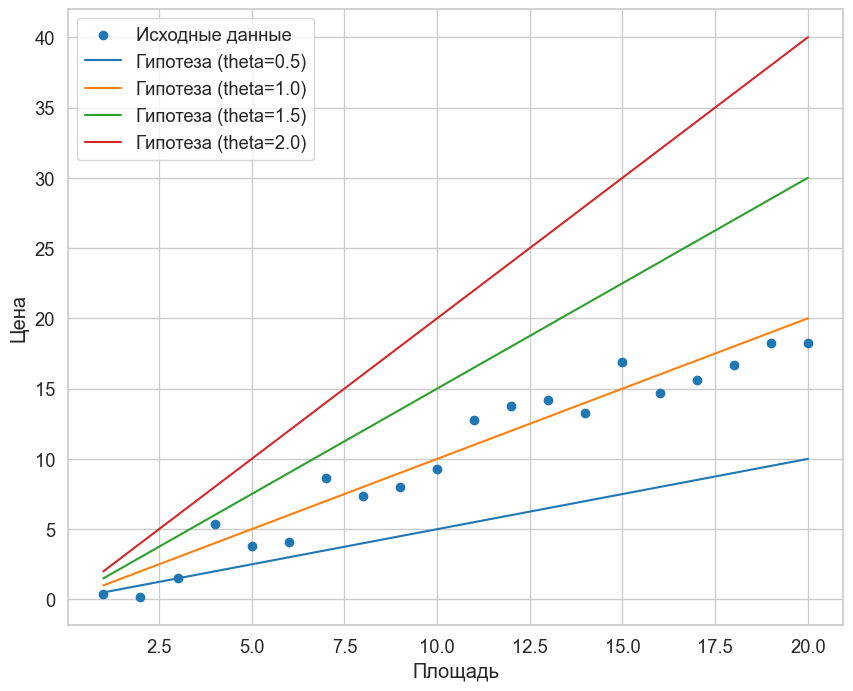

In [22]:
plt.scatter(xs2, ys2, label="Исходные данные")
thetas = [0.5, 1.0, 1.5, 2.0]
for theta in thetas:
    plt.plot(xs2, linear_regression(xs2, theta), label=f"Гипотеза (theta={theta})")
plt.legend()

plt.xlabel("Площадь")
plt.ylabel("Цена")
plt.show()

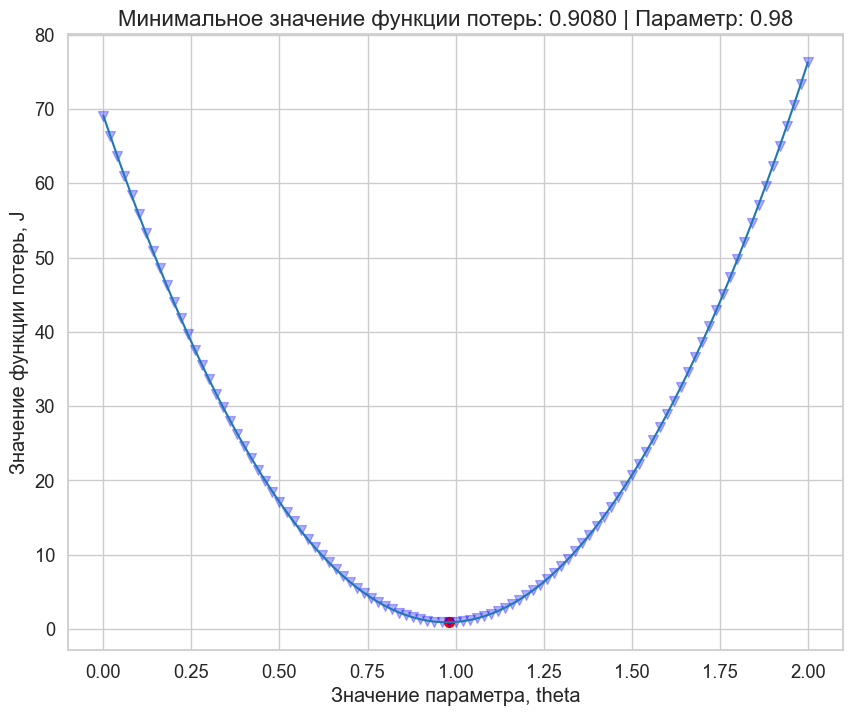

In [23]:
theta_data_2 = np.linspace(0, 2, 101)
cost_function_data_2 = [cost_function(xs2, ys2, theta) for theta in theta_data_2]

mask_2 = cost_function_data_2 == min(cost_function_data_2)
min_function_2 = np.array(cost_function_data_2)[mask_2]
min_theta_2 = np.array(theta_data_2)[mask_2]
plt.scatter(min_theta_2, min_function_2, color='red', s=50)

plt.plot(theta_data_2, cost_function_data_2)
plt.scatter(theta_data_2, cost_function_data_2, color='blue', alpha=0.3, s=50, marker="v")
plt.xlabel("Значение параметра, theta")
plt.ylabel("Значение функции потерь, J")
plt.title(f"Минимальное значение функции потерь: {min(cost_function_data_2):.4f} | Параметр: {min_theta_2[0]}", fontsize=16)

plt.show()

### Градиентный спуск

In [24]:
def cost_derivative(theta, xs, ys):
    return 1 / len(xs) * np.sum((linear_regression(xs, theta) - ys) * xs)

In [29]:
step_values = []
curr_theta = 0
learning_rate = 0.01

for i in range(10):
    step_values.append(curr_theta)
    new_theta = curr_theta - learning_rate * cost_derivative(curr_theta, xs2, ys2)
    curr_theta = new_theta

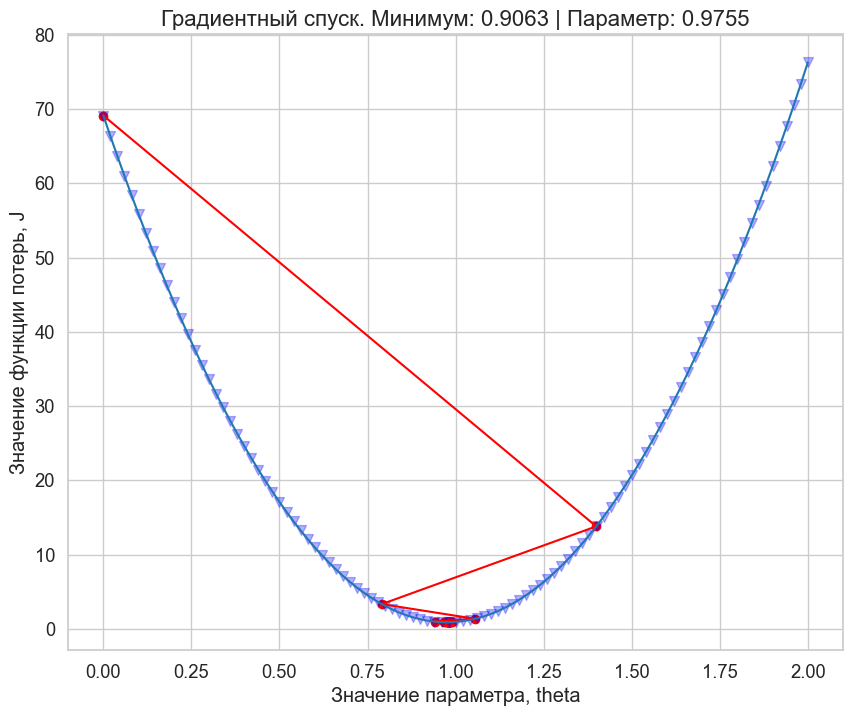

In [31]:
theta_data_2 = np.linspace(0, 2, 101)
cost_function_data_2 = [cost_function(xs2, ys2, theta) for theta in theta_data_2]

mask_2 = cost_function_data_2 == min(cost_function_data_2)
min_function_2 = np.array(cost_function_data_2)[mask_2]
min_theta_2 = np.array(theta_data_2)[mask_2]
plt.scatter(min_theta_2, min_function_2, color='red', s=50)

cost_function_steps = [cost_function(xs2, ys2, theta) for theta in step_values]
plt.scatter(step_values, cost_function_steps, color='red')
plt.plot(step_values, cost_function_steps, color="red")


plt.plot(theta_data_2, cost_function_data_2)
plt.scatter(theta_data_2, cost_function_data_2, color='blue', alpha=0.3, s=50, marker="v")
plt.xlabel("Значение параметра, theta")
plt.ylabel("Значение функции потерь, J")
plt.title(f"Градиентный спуск. Минимум: {cost_function_steps[-1]:.4f} | Параметр: {step_values[-1]:.4f}", fontsize=16)

plt.show()